In [2]:
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import seaborn as sns
from collections import Counter
from itertools import combinations, permutations

1.a

In [3]:
def configuration_model(degrees, seed=None):
    '''
    build a configuration graph from a degree sequence of non-negative integers
    take a node and give it stubs equal to its degree
    then randomly pair up the stubs to form edges
    return error for negative or non-integer degrees, or if the sum of degrees is odd
    make it reproducible with a seed for the random number generator
    '''
    if any(not isinstance(k, (int, np.integer)) or k < 0 for k in degrees):
        raise ValueError("Degrees must be non-negative integers.")
    if sum(degrees) % 2 != 0:
        raise ValueError("The sum of the degree sequence must be even.")
    rng = np.random.default_rng(seed)
    # node i appears k_i times in the stub list
    stubs = np.repeat(np.arange(len(degrees)), degrees)
    rng.shuffle(stubs)
    G = nx.MultiGraph()
    G.add_nodes_from(range(len(degrees)))
    # consecutive pairs of the shuffled stubs are the edges
    G.add_edges_from(stubs.reshape(-1, 2).tolist())
    return G

Let's test it a randomly generated degree sequence, with `seed=10` for reproducibility and visualize. Self-loops count twice toward a node's degree in a `MultiGraph`, so the output degrees should match the input exactly even if the graph has loops or parallel edges.

MultiGraph 8 nodes 22 edges
input:  [7, 9, 3, 2, 8, 8, 5, 2]
output: [7, 9, 3, 2, 8, 8, 5, 2]
degrees match: True
self-loops: [(0, 0), (1, 1), (4, 4), (5, 5), (6, 6)]
multiple edges (>1): {(0, 4): 2, (1, 5): 3, (5, 7): 2}


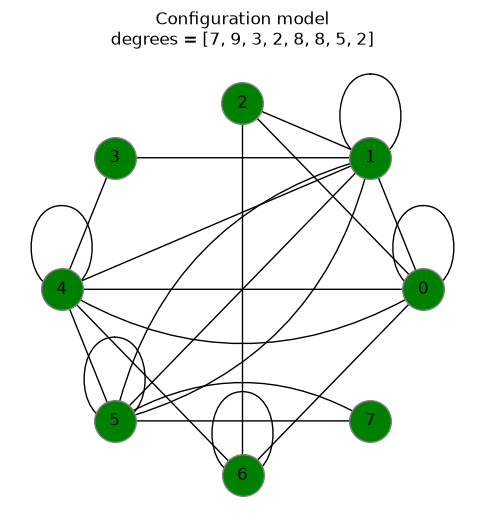

In [4]:
# random degree sequence: 8 degrees between 1 and 9, redrawn until the sum is even
rng = np.random.default_rng(10)
degrees = rng.integers(1, 10, size=8).tolist()
while sum(degrees) % 2 != 0:
    degrees = rng.integers(1, 10, size=8).tolist()

G = configuration_model(degrees, seed=10)
print(type(G).__name__, G.number_of_nodes(), "nodes", G.number_of_edges(), "edges")
print("input: ", degrees)
print("output:", [G.degree(i) for i in range(len(degrees))])
print("degrees match:", [G.degree(i) for i in range(len(degrees))] == degrees)
print("self-loops:", list(nx.selfloop_edges(G)))
print("multiple edges (>1):", {e: m for e, m in Counter(map(tuple, map(sorted, G.edges()))).items() if m > 1})

# circular layout visualization, us n.draw to see all the edges
pos = nx.circular_layout(G)
fig, ax = plt.subplots(figsize=(6, 6))
nx.draw_networkx_nodes(G, pos, node_color="green", edgecolors="grey", node_size=900, ax=ax)
nx.draw_networkx_labels(G, pos, ax=ax)
# MultiGraph edges are (u, v, key). we should draw each parallel copy with its own curvature
# so duplicates don't sit on top of each other. alternate sides with (-1)^k and scale the curvature with k.
for u, v, k in G.edges(keys=True):
    rad = 0 if k == 0 else 0.3 * (-1) ** k * ((k + 1) // 2)
    nx.draw_networkx_edges(G, pos, edgelist=[(u, v)], arrows=True, arrowstyle="-",
                           connectionstyle=f"arc3,rad={rad}", node_size=900, ax=ax)
ax.set_title(f"Configuration model\ndegrees = {degrees}")
ax.set_axis_off()
plt.show()

Now we can test for bad inputs. An odd sum can't be paired up, and negative or non-integer degrees make no sense, so these should all raise a ValueError.

In [5]:
# odd sum, negative degree, non-integer degree
for bad in ([1, 2], [1, -1], [1.0, 1]):
    try:
        configuration_model(bad)
    except ValueError as e:
        print(bad, "->", e)

[1, 2] -> The sum of the degree sequence must be even.
[1, -1] -> Degrees must be non-negative integers.
[1.0, 1] -> Degrees must be non-negative integers.


1.b

In [6]:
def chung_lu_model(degrees, seed=None):
    '''
    build a chung lu graph from a degree sequence of non-negative integers
    for every pair of nodes i < j, add an edge independently with probability k_i k_j / 2m
    cap the probability at 1, since hubs can push k_i k_j / 2m above 1
    return error for negative or non-integer degrees
    make it reproducible with a seed for the random number generator
    '''
    if any(not isinstance(k, (int, np.integer)) or k < 0 for k in degrees):
        raise ValueError("Degrees must be non-negative integers.")
    rng = np.random.default_rng(seed)
    # 2m is the sum of the degrees
    two_m = sum(degrees)
    G = nx.Graph()
    G.add_nodes_from(range(len(degrees)))
    # each pair is its own coin flip, and i < j so there are no self-loops or duplicate edges
    for i, j in combinations(range(len(degrees)), 2):
        if two_m > 0 and rng.random() < min(1, degrees[i] * degrees[j] / two_m):
            G.add_edge(i, j)
    return G

Let's test it on a randomly generated degree sequence, with `seed=10` for reproducibility and visualize. Each edge is an independent coin flip, so the output degrees will only be approximately the input. The output should be a simple graph, so there are no self-loops or parallel edges.

Graph 8 nodes 14 edges
input:  [7, 9, 3, 2, 8, 8, 5, 2]
output: [5, 4, 2, 2, 4, 5, 5, 1]
self-loops: []


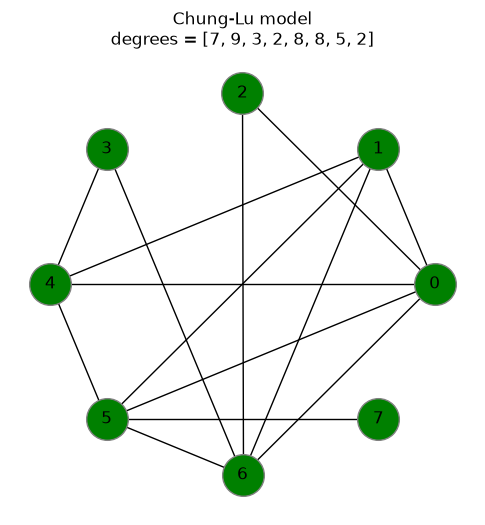

In [7]:
# random degree sequence: 8 degrees between 1 and 9
rng = np.random.default_rng(10)
degrees = rng.integers(1, 10, size=8).tolist()

G = chung_lu_model(degrees, seed=10)
print(type(G).__name__, G.number_of_nodes(), "nodes", G.number_of_edges(), "edges")
print("input: ", degrees)
print("output:", [G.degree(i) for i in range(len(degrees))])
# check for no self-loops
print("self-loops:", list(nx.selfloop_edges(G)))

# circular layout visualization
pos = nx.circular_layout(G)
fig, ax = plt.subplots(figsize=(6, 6))
nx.draw_networkx_nodes(G, pos, node_color="green", edgecolors="grey", node_size=900, ax=ax)
nx.draw_networkx_labels(G, pos, ax=ax)
# the graph is simple, so every edge can be drawn straight
nx.draw_networkx_edges(G, pos, node_size=900, ax=ax)
ax.set_title(f"Chung-Lu model\ndegrees = {degrees}")
ax.set_axis_off()
plt.show()

Now we can test for bad inputs. Negative or non-integer degrees make no sense, so these should both raise a ValueError. Unlike the configuration model, an odd sum is fine here since nothing has to be paired up.

In [8]:
# negative degree, non-integer degree
for bad in ([1, -1], [1.0, 1]):
    try:
        chung_lu_model(bad)
    except ValueError as e:
        print(bad, "->", e)

[1, -1] -> Degrees must be non-negative integers.
[1.0, 1] -> Degrees must be non-negative integers.


1.c.i

For the degree sequence from the assignment we sample $N = 1000$ graphs from each model (graph $i$ uses `seed=10+i`) and average their adjacency matrices to get $\langle A \rangle = \frac{1}{N}\sum_{i=1}^{N} A_i$. We  will make three versions: 1) the configuration model as is (a multigraph) 2) the configuration model with self-loops and duplicate edges dropped 3) Chung-Lu. In the multigraph a self-loop counts twice on the diagonal, so each row of $\langle A \rangle$ sums to that node's degree.

In [9]:
degrees_c = [8, 5, 5, 4, 3, 2, 2, 2, 1, 1, 1, 1, 1, 1, 1]
n = len(degrees_c)
N = 1000

# running sums of the adjacency matrices for each version
A_multi = np.zeros((n, n))
A_simple = np.zeros((n, n))
A_cl = np.zeros((n, n))
for i in range(N):
    G = configuration_model(degrees_c, seed=10 + i)
    # to_numpy_array counts a self-loop once, so double the diagonal to make each row sum to the degree
    A = nx.to_numpy_array(G)
    A[np.diag_indices(n)] *= 2
    A_multi += A
    # nx.Graph merges duplicate edges, then we drop the self-loops
    G_simple = nx.Graph(G)
    G_simple.remove_edges_from(nx.selfloop_edges(G_simple))
    A_simple += nx.to_numpy_array(G_simple)
    A_cl += nx.to_numpy_array(chung_lu_model(degrees_c, seed=10 + i))

# divide by N to get the average
A_multi, A_simple, A_cl = A_multi / N, A_simple / N, A_cl / N

We set up one figure with three panels stacked vertically, all on the same color scale. Each panel gets filled in by its own cell below.

In [10]:
# same color scale for every panel, from 0 to the largest entry of the three matrices
vmax = max(A_multi.max(), A_simple.max(), A_cl.max())
fig, axes = plt.subplots(3, 1, figsize=(6, 14), layout="constrained")
# close it so it isn't shown half-empty, we display it again once all three panels are drawn
plt.close(fig)

First panel: the true configuration model. Entries can be bigger than 1 since the same pair can be joined by several edges, and the diagonal is nonzero because of the self-loops.

In [11]:
axes[0].imshow(A_multi, cmap="viridis", vmin=0, vmax=vmax)
axes[0].set_title("Configuration model (multigraph)")
axes[0].set_xticks(range(n))
axes[0].set_yticks(range(n))
axes[0].set_xlabel("node j")
axes[0].set_ylabel("node i")

Text(0, 0.5, 'node i')

Second panel: the same configuration model graphs after dropping self-loops and collapsing duplicate edges. Now every entry is the probability of at least one edge, so the diagonal is empty and nothing is above 1.

In [12]:
axes[1].imshow(A_simple, cmap="viridis", vmin=0, vmax=vmax)
axes[1].set_title("Configuration model\n(self-loops and duplicate edges dropped)")
axes[1].set_xticks(range(n))
axes[1].set_yticks(range(n))
axes[1].set_xlabel("node j")
axes[1].set_ylabel("node i")

Text(0, 0.5, 'node i')

Third panel: the Chung-Lu model. Every entry is a probability, and the cap at 1 shows up for the hub pairs.

In [13]:
axes[2].imshow(A_cl, cmap="viridis", vmin=0, vmax=vmax)
axes[2].set_title("Chung-Lu model")
axes[2].set_xticks(range(n))
axes[2].set_yticks(range(n))
axes[2].set_xlabel("node j")
axes[2].set_ylabel("node i")

Text(0, 0.5, 'node i')

Now we add a single colorbar shared by all three panels and display the figure.

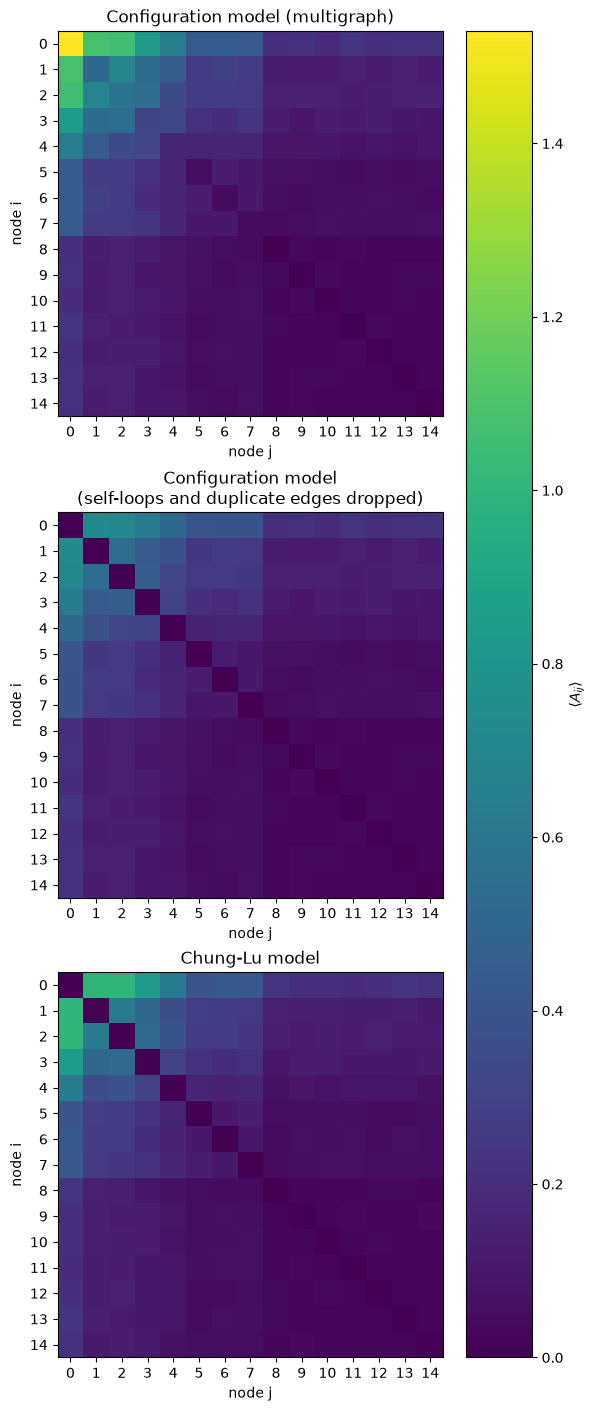

In [14]:
# one colorbar for all three panels, then display the finished figure
fig.colorbar(axes[0].images[0], ax=axes, label=r"$\langle A_{ij} \rangle$")
fig.savefig("configuration_chunglu_heatmaps.png", dpi=300)
fig

1.c.ii

Here is the metric that should **diverge**: the number of isolated nodes (degree 0) in a graph.

We plot the CCDF, $P(X \geq x)$, where $X$ is the number of isolated nodes in one graph, for all three versions of the model from 1.c.i (same seeds as before).

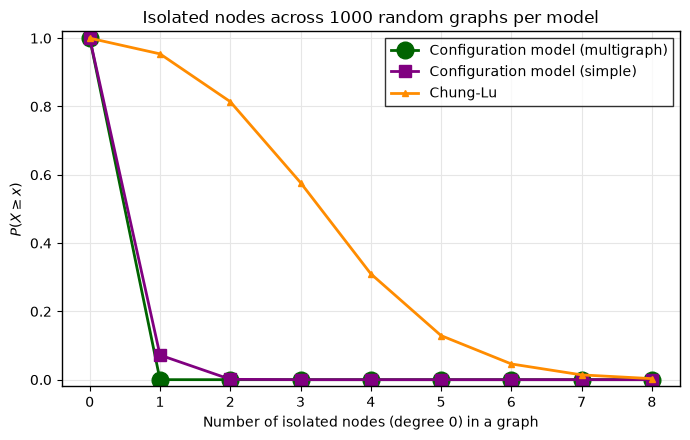

Configuration model (multigraph): mean = 0.000, P(X >= 1) = 0.000, max = 0
Configuration model (simple): mean = 0.073, P(X >= 1) = 0.072, max = 2
Chung-Lu: mean = 2.847, P(X >= 1) = 0.954, max = 8


In [15]:
def count_isolated(G):
    # nodes with degree 0. a self-loop counts twice in a MultiGraph, so loops keep a node non-isolated there
    return sum(1 for _, k in G.degree() if k == 0)

# regenerate the same 1000 graphs per model (same seeds as 1.c.i) and count isolated nodes in each
iso = {"Configuration model (multigraph)": [],
       "Configuration model (simple)": [],
       "Chung-Lu": []}
for i in range(N):
    G = configuration_model(degrees_c, seed=10 + i)
    iso["Configuration model (multigraph)"].append(count_isolated(G))
    # drop self-loops and duplicate edges, a deleted loop can leave a degree-2 node isolated
    G_simple = nx.Graph(G)
    G_simple.remove_edges_from(nx.selfloop_edges(G_simple))
    iso["Configuration model (simple)"].append(count_isolated(G_simple))
    iso["Chung-Lu"].append(count_isolated(chung_lu_model(degrees_c, seed=10 + i)))

def ccdf(values, xmax):
    # P(X >= x) at every integer x from 0 to xmax
    values = np.asarray(values)
    x = np.arange(xmax + 1)
    return x, np.array([(values >= k).mean() for k in x])

colors = {"Configuration model (multigraph)": "darkgreen",
          "Configuration model (simple)": "purple",
          "Chung-Lu": "darkorange"}
# nested marker sizes so overlapping points (everything sits at P = 1 when x = 0) stay visible
markers = {"Configuration model (multigraph)": ("o", 12),
           "Configuration model (simple)": ("s", 8),
           "Chung-Lu": ("^", 5)}

# theme_bw-ish: white panel, light gray grid, black border
with plt.rc_context({"axes.facecolor": "white", "axes.edgecolor": "black", "axes.linewidth": 1,
                     "axes.grid": True, "grid.color": "0.9", "axes.axisbelow": True,
                     "axes.spines.top": True, "axes.spines.right": True}):
    fig, ax = plt.subplots(figsize=(7, 4.5))
    xmax = max(max(v) for v in iso.values())
    for name, vals in iso.items():
        x, p = ccdf(vals, xmax)
        m, ms = markers[name]
        ax.plot(x, p, marker=m, markersize=ms, linewidth=2, color=colors[name], label=name)
    ax.set_xlabel("Number of isolated nodes (degree 0) in a graph")
    ax.set_ylabel(r"$P(X \geq x)$")
    ax.set_title("Isolated nodes across 1000 random graphs per model")
    ax.set_xticks(range(xmax + 1))
    ax.set_ylim(-0.02, 1.02)
    ax.legend(frameon=True, edgecolor="black", fancybox=False)
    fig.tight_layout()
    fig.savefig("isolated_nodes_ccdf.png", dpi=300)
    plt.show()

for name, vals in iso.items():
    vals = np.array(vals)
    print(f"{name}: mean = {vals.mean():.3f}, P(X >= 1) = {(vals >= 1).mean():.3f}, max = {vals.max()}")

Now the metric that should be **about the same** under both models: the number of nodes with degree exactly 4 in a graph. This is the same kind of count as before (nodes with degree $k$), just at a different $k$. For $k = 0$ the models disagree, and in the middle of the degree range we expect them to mostly agree.

Reading the plot below: the input sequence has exactly one node of degree 4, so the configuration multigraph will always have exactly one (its degrees are exact). The two simple graphs can be above or below that, since degrees move around once duplicate edges are collapsed (configuration model) or edges are flipped independently (Chung-Lu), so what we compare is whether those two distributions look alike. We reuse the 1000 graphs per model, the CCDF helper, and the colors from the previous plot.

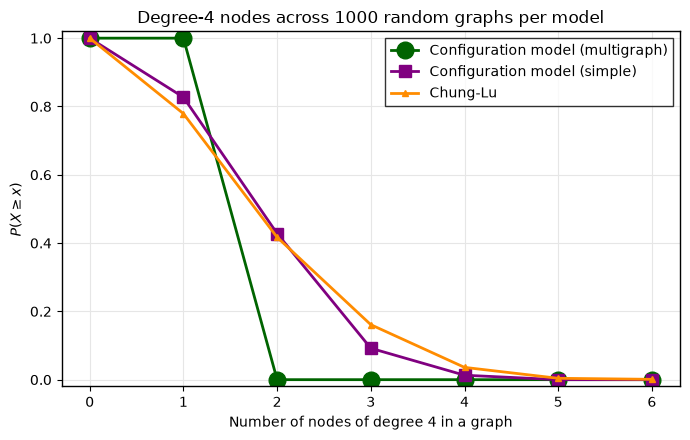

Configuration model (multigraph): mean = 1.000, sd = 0.000, max = 1
Configuration model (simple): mean = 1.360, sd = 0.901, max = 4
Chung-Lu: mean = 1.398, sd = 1.086, max = 6


In [16]:
def count_degree(G, k):
    # number of nodes with degree exactly k
    return sum(1 for _, d in G.degree() if d == k)

# regenerate the same 1000 graphs per model (same seeds as before) and count the nodes of degree 4
k4 = {"Configuration model (multigraph)": [],
      "Configuration model (simple)": [],
      "Chung-Lu": []}
for i in range(N):
    G = configuration_model(degrees_c, seed=10 + i)
    k4["Configuration model (multigraph)"].append(count_degree(G, 4))
    G_simple = nx.Graph(G)
    G_simple.remove_edges_from(nx.selfloop_edges(G_simple))
    k4["Configuration model (simple)"].append(count_degree(G_simple, 4))
    k4["Chung-Lu"].append(count_degree(chung_lu_model(degrees_c, seed=10 + i), 4))

# same theme_bw-ish style, ccdf helper, colors, and nested markers as the isolated-nodes plot
with plt.rc_context({"axes.facecolor": "white", "axes.edgecolor": "black", "axes.linewidth": 1,
                     "axes.grid": True, "grid.color": "0.9", "axes.axisbelow": True,
                     "axes.spines.top": True, "axes.spines.right": True}):
    fig, ax = plt.subplots(figsize=(7, 4.5))
    xmax = max(max(v) for v in k4.values())
    for name, vals in k4.items():
        x, p = ccdf(vals, xmax)
        m, ms = markers[name]
        ax.plot(x, p, marker=m, markersize=ms, linewidth=2, color=colors[name], label=name)
    ax.set_xlabel("Number of nodes of degree 4 in a graph")
    ax.set_ylabel(r"$P(X \geq x)$")
    ax.set_title("Degree-4 nodes across 1000 random graphs per model")
    ax.set_xticks(range(xmax + 1))
    ax.set_ylim(-0.02, 1.02)
    ax.legend(frameon=True, edgecolor="black", fancybox=False)
    fig.tight_layout()
    fig.savefig("degree4_nodes_ccdf.png", dpi=300)
    plt.show()

for name, vals in k4.items():
    vals = np.array(vals)
    print(f"{name}: mean = {vals.mean():.3f}, sd = {vals.std():.3f}, max = {vals.max()}")

2.a

First, we will important ensure we understand structure of the data from the EU research email network. 

In [17]:
# directed edge list each line is "source target", no header
edges = pd.read_csv("EU Email network/email-Eu-core.txt", sep=r"\s+", header=None, names=["source", "target"])
# one department label per node: "node department"
labels = pd.read_csv("EU Email network/email-Eu-core-department-labels.txt", sep=r"\s+", header=None, names=["node", "department"])

# add every labeled node first so none can go missing, then the edges, then the department attribute
D = nx.DiGraph()
D.add_nodes_from(labels["node"])
D.add_edges_from(zip(edges["source"], edges["target"]))
nx.set_node_attributes(D, labels.set_index("node")["department"].to_dict(), "department")

Now we check what we loaded. The file should be a directed graph on 1005 nodes with one department label per node. We also will look at things that matter for community detection later, self-loops (someone emailing themselves), how much of the graph is reciprocated, and how big the departments are.

In [18]:
print(f"nodes: {D.number_of_nodes()}, directed edges: {D.number_of_edges()}")
print("rows in the edge file:", len(edges), "| duplicate rows:", edges.duplicated().sum())
print("nodes without a department:", sum("department" not in d for _, d in D.nodes(data=True)))

# self-loops, and how many of the directed edges are reciprocated (mutual ties)
n_loops = nx.number_of_selfloops(D)
n_recip = sum(1 for u, v in D.edges() if u != v and D.has_edge(v, u))
print(f"self-loops: {n_loops}")
print(f"reciprocated edges (excluding loops): {n_recip} of {D.number_of_edges() - n_loops}")
print("nodes with in-degree 0:", sum(1 for n in D if D.in_degree(n) == 0),
      "| out-degree 0:", sum(1 for n in D if D.out_degree(n) == 0))
print("weakly connected components:", nx.number_weakly_connected_components(D))

# department sizes
dept_sizes = Counter(nx.get_node_attributes(D, "department").values())
print(f"\ndepartments: {len(dept_sizes)}")
print("five largest (department: nodes):", dept_sizes.most_common(5))
print("number of singleton departments:", sum(1 for s in dept_sizes.values() if s == 1))

nodes: 1005, directed edges: 25571
rows in the edge file: 25571 | duplicate rows: 0
nodes without a department: 0
self-loops: 642
reciprocated edges (excluding loops): 17730 of 24929
nodes with in-degree 0: 14 | out-degree 0: 137
weakly connected components: 20

departments: 42
five largest (department: nodes): [(4, 109), (14, 92), (1, 65), (21, 61), (15, 55)]
number of singleton departments: 2


Since this exercise is only about community detection, we will simplify the network in a few ways to allow for specific algos to be used
1. Drop every self-loop (an email to oneself says nothing about who talks to whom, and thus nothing about communities), then drop the nodes that only had self-loops and are now isolated, since they can't belong to any community.
2. Drop edge direction, so we have an undirected graph, to assist modularity calculation.
3. Remove the duplicate edges that dropping direction creates (a mutual pair $a \to b$, $b \to a$ becomes two copies of the same edge). `nx.Graph` already keeps one edge per pair, so steps 2 and 3 happen together.

We keep the department labels on the nodes. They are the ground truth we can compare the detected communities against later, so we also save them as a `{node_id: department}` dictionary.

In [19]:
# 1) drop self-loops, then drop the nodes that only had self-loops and are now isolated
D_clean = D.copy()
D_clean.remove_edges_from(nx.selfloop_edges(D_clean))
isolated = list(nx.isolates(D_clean))
D_clean.remove_nodes_from(isolated)
print(f"after dropping self-loops: removed {n_loops} edges, then {len(isolated)} isolated nodes")

# 2) + 3) drop direction. nx.Graph keeps one edge per pair, so a mutual pair (a -> b and b -> a) collapses to one edge
G_email = nx.Graph(D_clean)
print(f"undirected graph: {G_email.number_of_nodes()} nodes, {G_email.number_of_edges()} edges")
print(f"mutual pairs collapsed into a single edge: {D_clean.number_of_edges() - G_email.number_of_edges()}")
print("connected components:", nx.number_connected_components(G_email))

# ground truth to compare against after community detection: {node_id: department}
ground_truth = nx.get_node_attributes(G_email, "department")
print("departments left:", len(set(ground_truth.values())), "; is every node still labeled:", len(ground_truth) == G_email.number_of_nodes())

after dropping self-loops: removed 642 edges, then 19 isolated nodes
undirected graph: 986 nodes, 16064 edges
mutual pairs collapsed into a single edge: 8865
connected components: 1
departments left: 42 ; is every node still labeled: True



At this point, while looking into NetworkX documentation, I realized a directed implementation of Louvain also exists, so I thought we could test and visualize both the directed version on `D_clean` and the undirected on `G_email`. We'll run both off the same seed and store the partitions to compare. 

In [20]:
def to_partition(communities):
    # list of node sets -> {node_id: community_id}
    return {node: cid for cid, comm in enumerate(communities) for node in comm}

# undirected Louvain on G_email (the simplified graph), directed Louvain on D_clean (same nodes, keeps edge direction)
# sort the communities by size so that community 0 is the largest in both
comms_und = sorted(nx.community.louvain_communities(G_email, seed=10), key=len, reverse=True)
comms_dir = sorted(nx.community.louvain_communities(D_clean, seed=10), key=len, reverse=True)
partition_und = to_partition(comms_und)
partition_dir = to_partition(comms_dir)

# modularity is computed with each graph's own definition (the directed one for D_clean), so the two are not strictly comparable
print(f"undirected Louvain on G_email: {len(comms_und)} communities, modularity = {nx.community.modularity(G_email, comms_und):.3f}")
print(f"directed Louvain on D_clean:   {len(comms_dir)} communities, modularity = {nx.community.modularity(D_clean, comms_dir):.3f}")
print("undirected community sizes:", [len(c) for c in comms_und])
print("directed community sizes:  ", [len(c) for c in comms_dir])

undirected Louvain on G_email: 8 communities, modularity = 0.413
directed Louvain on D_clean:   6 communities, modularity = 0.427
undirected community sizes: [179, 176, 141, 131, 125, 108, 94, 32]
directed community sizes:   [327, 240, 146, 116, 95, 62]


In [21]:
# louvain is randomized, so one seed can mislead. repeat both runs over 20 seeds
sweep = []
for s in range(20):
    cu = nx.community.louvain_communities(G_email, seed=s)
    cd = nx.community.louvain_communities(D_clean, seed=s)
    sweep.append({"communities (undirected)": len(cu), "communities (directed)": len(cd),
                  "modularity (undirected)": nx.community.modularity(G_email, cu),
                  "modularity (directed)": nx.community.modularity(D_clean, cd)})
pd.DataFrame(sweep).agg(["mean", "std", "min", "max"]).T.round(3)

,mean,std,min,max
communities (undirected),7.700,0.733,6.000,9.000
communities (directed),7.500,0.607,6.000,8.000
modularity (undirected),0.413,0.002,0.408,0.417
modularity (directed),0.427,0.002,0.420,0.429


The two detection outputs look slightly different when computed with a single seed, here there were more communities for the undirected Louvain. The 20-seed table above shows that iteration shows this is mostly random noise. Over 20 runs both versions find about 7.5 to 8 communities (7.7 undirected, 7.5 directed). So keeping edge direction does not change how many communities are broadly arising. Furthermore, the consistenly larger directed community sizes indicate to me that its highly likely the directed communities are encompassing the nodes of the undirected ones, and dropping directionality is probably breaking apart some communities, leading both to the higher mean and higher max number of communities found in the iteration runs. Overall, I'm going to continue with `D_clean`, the directed version of the network with self loops dropped, and isolated nodes dropeed after that. 

The directed modularity is consistently higher, but I don't think we are able to read that as the directed run being better, since the two numbers come from different modularity formulas on different graphs, and I have not looked deeper into the mathematical derivation of the directed function.

2.a

Now we can try visualize both partitions, following the class 07 examples: a spring layout, nodes colored by community with a colormap, and no node labels (there are too many nodes). Both panels share one layout, computed once on the undirected graph (same nodes as `D_clean`), so only the colors differ between them. `D_clean` has about 25k directed edges, so arrowheads would be unreadable and its edges are drawn as plain faint lines. Communities are numbered by size in each run, so color 0 is the largest community in both panels, but the same color in the two panels does not mean the same community.

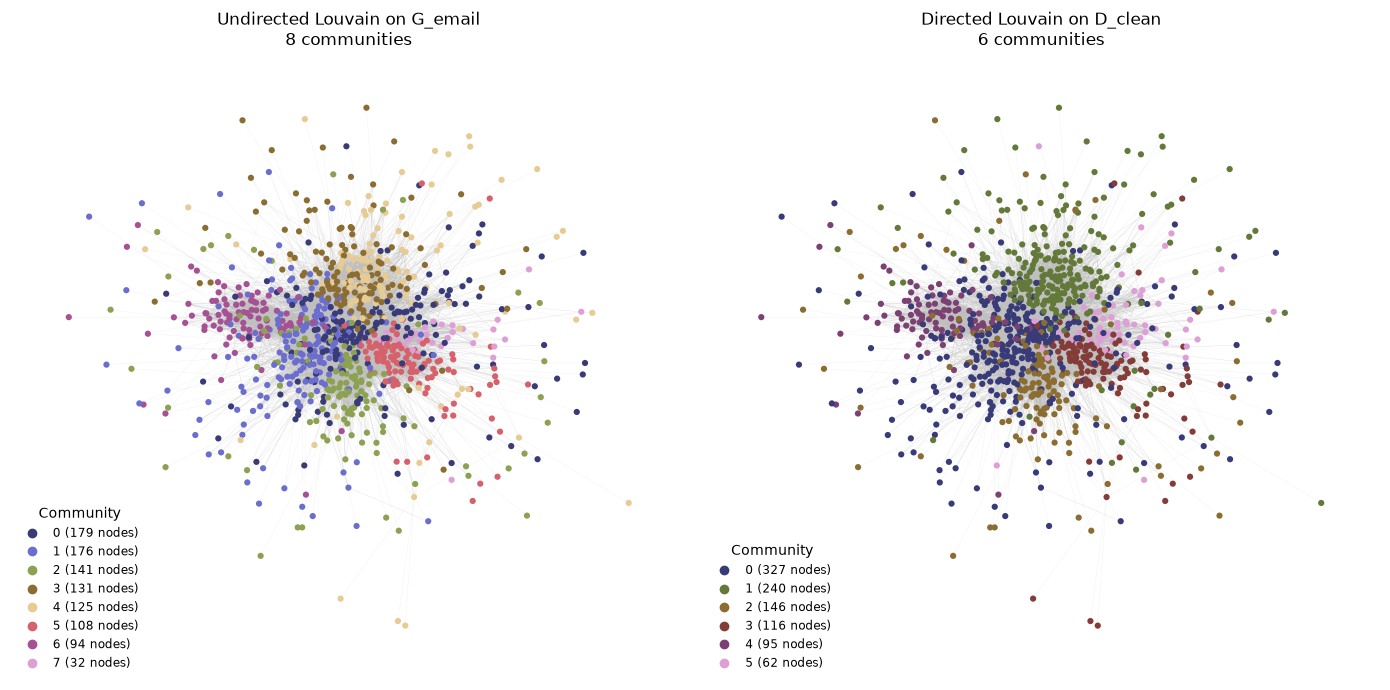

In [22]:
from matplotlib.lines import Line2D
pos_email = nx.spring_layout(G_email, seed=10)
def community_colors(partition):
    ids = np.unique(list(partition.values()))
    palette = dict(zip(ids, plt.cm.tab20b(np.linspace(0, 1, len(ids)))))
    return [palette[partition[n]] for n in D_clean.nodes()], palette
panels = [(partition_und, "Undirected Louvain on G_email"),
          (partition_dir, "Directed Louvain on D_clean")]
fig, axes = plt.subplots(1, 2, figsize=(14, 7), dpi=100)
for ax, (partition, title) in zip(axes, panels):
    node_colors, palette = community_colors(partition)
    sizes = Counter(partition.values())
    # D_clean is directed, but with ~25k edges arrowheads are unreadable, so edges are drawn as plain faint lines
    nx.draw_networkx_edges(D_clean, pos_email, arrows=False, edge_color="0.75", width=0.2, alpha=0.3, ax=ax)
    nx.draw_networkx_nodes(D_clean, pos_email, node_color=node_colors, node_size=20, linewidths=0, ax=ax)
    # legend: community id (sorted by size, so 0 is the largest) and how many nodes it has
    handles = [Line2D([0], [0], marker="o", linestyle="", color=palette[c], label=f"{c} ({sizes[c]} nodes)")
               for c in sorted(palette)]
    ax.legend(handles=handles, title="Community", loc="lower left", fontsize="small", frameon=False)
    ax.set_title(f"{title}\n{len(palette)} communities", fontsize="large")
    ax.set_axis_off()
fig.tight_layout()
fig.savefig("email_communities.png", dpi=300)
plt.show()

The plain spring layout above piles most of the nodes into one hairball. Here is the same figure with a layout that uses the communities: edges inside a community pull 10 times harder than edges between communities, so each community clusters into its own region. The communities now shape the node positions, so the clustering in the picture is partly built in.  

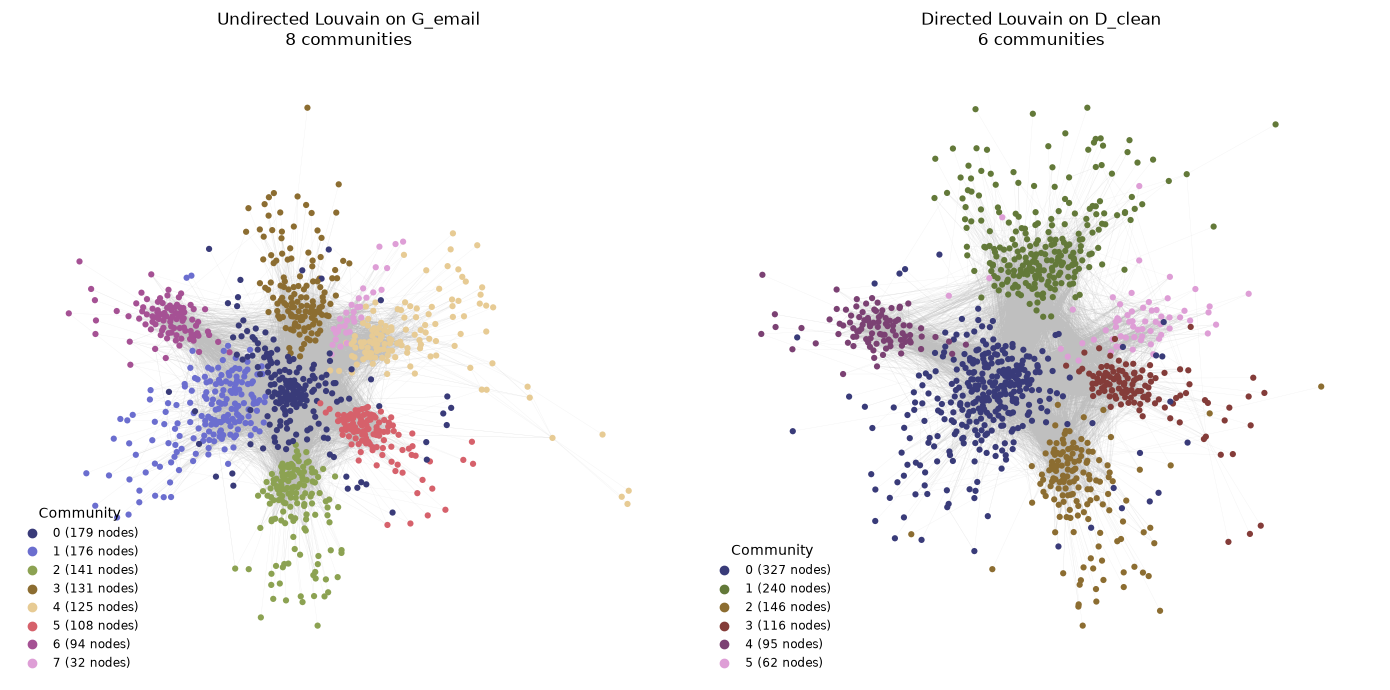

In [23]:
def weighted_layout(G, partition, intra=10, seed=10):
    # spring layout where edges inside a community pull `intra` times harder than edges between communities
    H = nx.Graph()
    H.add_nodes_from(G)
    for u, v in G.edges():
        H.add_edge(u, v, weight=intra if partition[u] == partition[v] else 1)
    return nx.spring_layout(H, weight="weight", seed=seed)

fig, axes = plt.subplots(1, 2, figsize=(14, 7), dpi=100)
for ax, (partition, title) in zip(axes, panels):
    # each panel gets its own layout, built from its own partition (G_email has the same nodes and pairs as D_clean)
    pos_comm = weighted_layout(G_email, partition)
    node_colors, palette = community_colors(partition)
    sizes = Counter(partition.values())
    nx.draw_networkx_edges(D_clean, pos_comm, arrows=False, edge_color="0.75", width=0.2, alpha=0.25, ax=ax)
    nx.draw_networkx_nodes(D_clean, pos_comm, node_color=node_colors, node_size=20, linewidths=0, ax=ax)
    handles = [Line2D([0], [0], marker="o", linestyle="", color=palette[c], label=f"{c} ({sizes[c]} nodes)")
               for c in sorted(palette)]
    ax.legend(handles=handles, title="Community", loc="lower left", fontsize="small", frameon=False)
    ax.set_title(f"{title}\n{len(palette)} communities", fontsize="large")
    ax.set_axis_off()

fig.tight_layout()
fig.savefig("email_communities_weighted.png", dpi=300)
plt.show()

this is a little better, we can "see" the communities now, but its still too difficult to get an intuitive feel for the "shape" of the network, since there is no underlying logic to the spatial layout. I think we should try to add some of the ground truth (the true department affiliations) to check against our fewer communities (are the identified communities generally a union of entire departments? or are we splitting real departments?) 

To see how the departments relate to the communities we use two views side by side, both for the directed Louvain partition on `D_clean`. A node-level layout with 42 departments does not work well, it is too messy with various departments piling on top of one another, so the left panel works at the department level instead (hopefully a similar idea to louvain's collapsed nodes). Each department is one circle (area proportional to its number of nodes), placed by how much email goes between departments, with the strongest third of department pairs joined by a line. Each circle is a pie showing which communities that department's nodes landed in, using the same colors as before. The right panel is the same information as a table: one row per department, one column per community, each cell the share of that department's nodes in that community, with rows ordered by their main community so that departments sitting in one community line up in blocks. This reuses some definitions from earlier plotting cells.

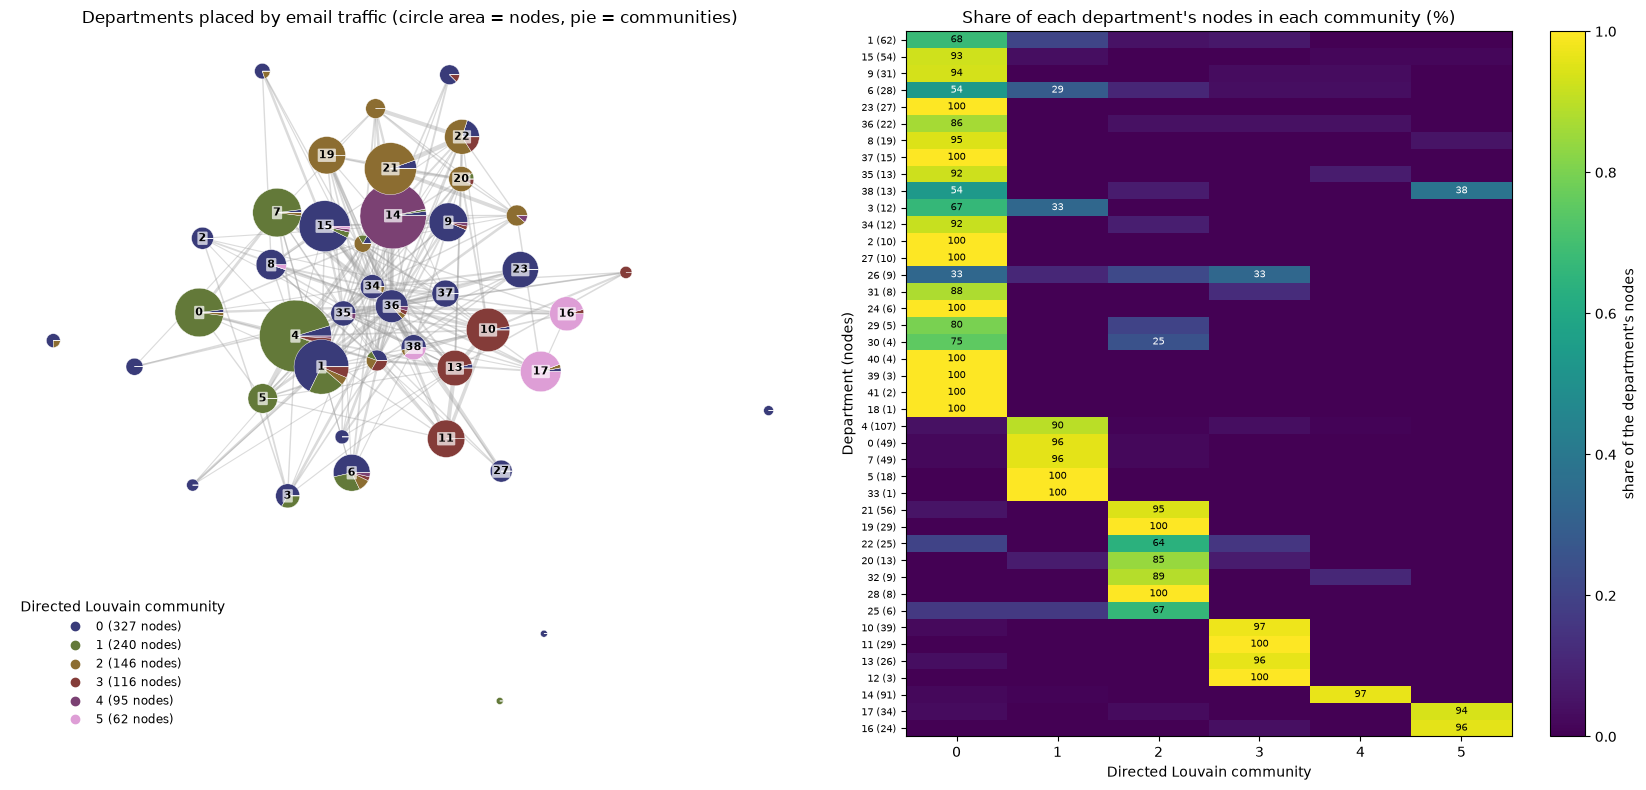

In [24]:
# share of each department's nodes that ends up in each directed-Louvain community, with rows summing to 1
share = pd.crosstab(pd.Series(ground_truth, name="department"), pd.Series(partition_dir, name="community"), normalize="index")
dept_n = pd.Series(ground_truth).value_counts()
# order departments by their main community, then by size, so departments that sit in one community line up in blocks
order = sorted(share.index, key=lambda d: (share.loc[d].idxmax(), -dept_n[d]))
_, palette = community_colors(partition_dir)
comm_sizes = Counter(partition_dir.values())
# department-level network: one node per department, edge weight = emails between two departments
between = Counter()
for u, v in G_email.edges():
    du, dv = ground_truth[u], ground_truth[v]
    if du != dv:
        between[tuple(sorted((du, dv)))] += 1
H = nx.Graph()
H.add_nodes_from(dept_n.index)
for (a, b), w in between.items():
    # divide by sqrt(size_a * size_b), adjusting so that two large departments don't look close just because they are large
    H.add_edge(a, b, weight=w / np.sqrt(dept_n[a] * dept_n[b]))
pos_dept = nx.spring_layout(H, weight="weight", seed=10, k=1.2)

fig, (ax_net, ax_heat) = plt.subplots(1, 2, figsize=(17, 8), dpi=100, gridspec_kw={"width_ratios": [1.1, 1]})

# left: each department is a pie of the communities its nodes ended up in. circle area = department size
weights = [d["weight"] for _, _, d in H.edges(data=True)]
cut = np.quantile(weights, 0.66)
for a, b, d in H.edges(data=True):
    # only the strongest third of department pairs get a line, thicker for stronger ties; otherwise too messy
    if d["weight"] >= cut:
        ax_net.plot(*zip(pos_dept[a], pos_dept[b]), color="0.6", alpha=0.35, lw=0.4 + 3 * d["weight"] / max(weights), zorder=1)
for d in dept_n.index:
    ax_net.pie(share.loc[d].values, colors=[palette[c] for c in share.columns], center=pos_dept[d],
               radius=0.009 * np.sqrt(dept_n[d]), frame=True, wedgeprops=dict(linewidth=0.3, edgecolor="white"))
    # label only departments with 10+ nodes, the rest are too small to hold a label
    if dept_n[d] >= 10:
        ax_net.text(*pos_dept[d], str(d), ha="center", va="center", fontsize=8, fontweight="bold",
                    bbox=dict(boxstyle="round,pad=0.1", fc="white", ec="none", alpha=0.7), zorder=5)
handles = [Line2D([0], [0], marker="o", linestyle="", color=palette[c], label=f"{c} ({comm_sizes[c]} nodes)")
           for c in sorted(palette)]
ax_net.legend(handles=handles, title="Directed Louvain community", loc="lower left", fontsize="small", frameon=False)
ax_net.set_aspect("equal")
ax_net.set_axis_off()
ax_net.set_title("Departments placed by email traffic (circle area = nodes, pie = communities)")
# right: the same information as a table of shares, one row per department
im = ax_heat.imshow(share.loc[order].values, cmap="viridis", vmin=0, vmax=1, aspect="auto")
ax_heat.set_xticks(range(share.shape[1]), share.columns)
ax_heat.set_yticks(range(len(order)), [f"{d} ({dept_n[d]})" for d in order], fontsize=7)
# write the share (%) inside every cell that holds at least a quarter of a department
for i, d in enumerate(order):
    for j, c in enumerate(share.columns):
        if share.loc[d, c] >= 0.25:
            ax_heat.text(j, i, f"{100 * share.loc[d, c]:.0f}", ha="center", va="center", fontsize=7,
                         color="white" if share.loc[d, c] < 0.6 else "black")
ax_heat.set_xlabel("Directed Louvain community")
ax_heat.set_ylabel("Department (nodes)")
ax_heat.set_title("Share of each department's nodes in each community (%)")
fig.colorbar(im, ax=ax_heat, label="share of the department's nodes")

fig.tight_layout()
fig.savefig("email_departments_vs_communities.png", dpi=300)
plt.show()

I think both of these have come out quite well, and are far more useful than the initial visualizations. We can easily see how the final communities are reflected as mainly unions of entire departments via the heatmap, with suprisingly few splits. 

2.b

For the null model we want a degree preserving randomization of `D_clean` that keeps every node's in-degree and out-degree, since those are what the directed modularity compares the real network against. 

Directed edge swaps (`nx.directed_edge_swap`) ensures that every in-degree and out-degree stays exactly the same, the graph stays simple, and the nodes and edge count are unchanged. We randomize `D_clean`, so the null goes through the same cleaning and keeps edge direction, and then we run the same directed Louvain on it. After a few iterations of testing levels of swapping, i found that the share of edges that match the original levels off at about 15% after 5 swaps per edge (it does not go to zero since hub pairs are likely to be connected by chance), so we use 5 swaps per edge.

One thing to keep in mind is that the swaps also scramble reciprocity (a->b, b->a) so any gap between the real network and the null reflects the mutual ties as well as the community structure.

In [25]:
n_edges = D_clean.number_of_edges()
# we aim for 5 swaps per edge so the wiring is well mixed
D_null = D_clean.copy()
nx.directed_edge_swap(D_null, nswap=5 * n_edges, max_tries=100 * n_edges, seed=10)
# checks: degrees unchanged, still a simple graph, ratio of the original edges that survived, and reciprocity
same_degrees = all(D_null.in_degree(n) == D_clean.in_degree(n) and D_null.out_degree(n) == D_clean.out_degree(n) for n in D_clean)
print("every in-degree and out-degree preserved:", same_degrees)
print("nodes | edges:", D_null.number_of_nodes(), "|", D_null.number_of_edges(), "| self-loops:", nx.number_of_selfloops(D_null))
print(f"edges shared with D_clean: {len(set(D_null.edges()) & set(D_clean.edges()))} of {n_edges}")
print(f"reciprocity: D_clean = {nx.reciprocity(D_clean):.3f}, D_null = {nx.reciprocity(D_null):.3f}")

# same directed Louvain run as before (same seed), stored as {node_id: community_id} as required by the question
comms_null = sorted(nx.community.louvain_communities(D_null, seed=10), key=len, reverse=True)
partition_null = to_partition(comms_null)
print(f"directed Louvain on D_null: {len(comms_null)} communities, modularity = {nx.community.modularity(D_null, comms_null):.3f}")
print("community sizes:", [len(c) for c in comms_null])

every in-degree and out-degree preserved: True
nodes | edges: 986 | 24929 | self-loops: 0
edges shared with D_clean: 3687 of 24929
reciprocity: D_clean = 0.711, D_null = 0.133
directed Louvain on D_null: 8 communities, modularity = 0.100
community sizes: [152, 146, 145, 133, 129, 123, 81, 77]


In [26]:
# one randomization is again only a single representation, so repeat with 20 independent nulls (swap seed and louvain seed both = s)
# and compare with directed Louvain on the real D_clean over the same 20 louvain seeds
rows = []
for s in range(20):
    D_s = D_clean.copy()
    nx.directed_edge_swap(D_s, nswap=5 * n_edges, max_tries=100 * n_edges, seed=s)
    c_null = nx.community.louvain_communities(D_s, seed=s)
    c_real = nx.community.louvain_communities(D_clean, seed=s)
    rows.append({"communities (real)": len(c_real), "communities (null)": len(c_null),
                 "modularity (real)": nx.community.modularity(D_clean, c_real), "modularity (null)": nx.community.modularity(D_s, c_null),
                 "largest community (real)": max(len(c) for c in c_real), "largest community (null)": max(len(c) for c in c_null)})
pd.DataFrame(rows).agg(["mean", "std", "min", "max"]).T.round(3)

,mean,std,min,max
communities (real),7.500,0.607,6.000,8.000
communities (null),10.150,0.988,8.000,12.000
modularity (real),0.427,0.002,0.420,0.429
modularity (null),0.094,0.002,0.091,0.100
largest community (real),269.750,32.376,221.000,329.000
largest community (null),140.000,13.815,116.000,170.000


So we can clearly see that the rewiring has destroyed the community structure we had identified. The number of communities is higher, with wider spread. Modularity is far lower, and community size has naturally shrunk as well. 

2.c

First we should repeat the department figure from 2.a for the randomized network, using `partition_null`. Everything else is kept the same so the two figures can be compared directly: the department circles stay where the real email traffic puts them (spatially), the heatmap rows keep the same department order as the real-network heatmap, and the color scale is identical. The pies and the heatmap columns now show the communities found in the edge-swap null (there are more of them, so the colors are different from the real-network figure). This reuses certain items from the earlier department plotting cell.

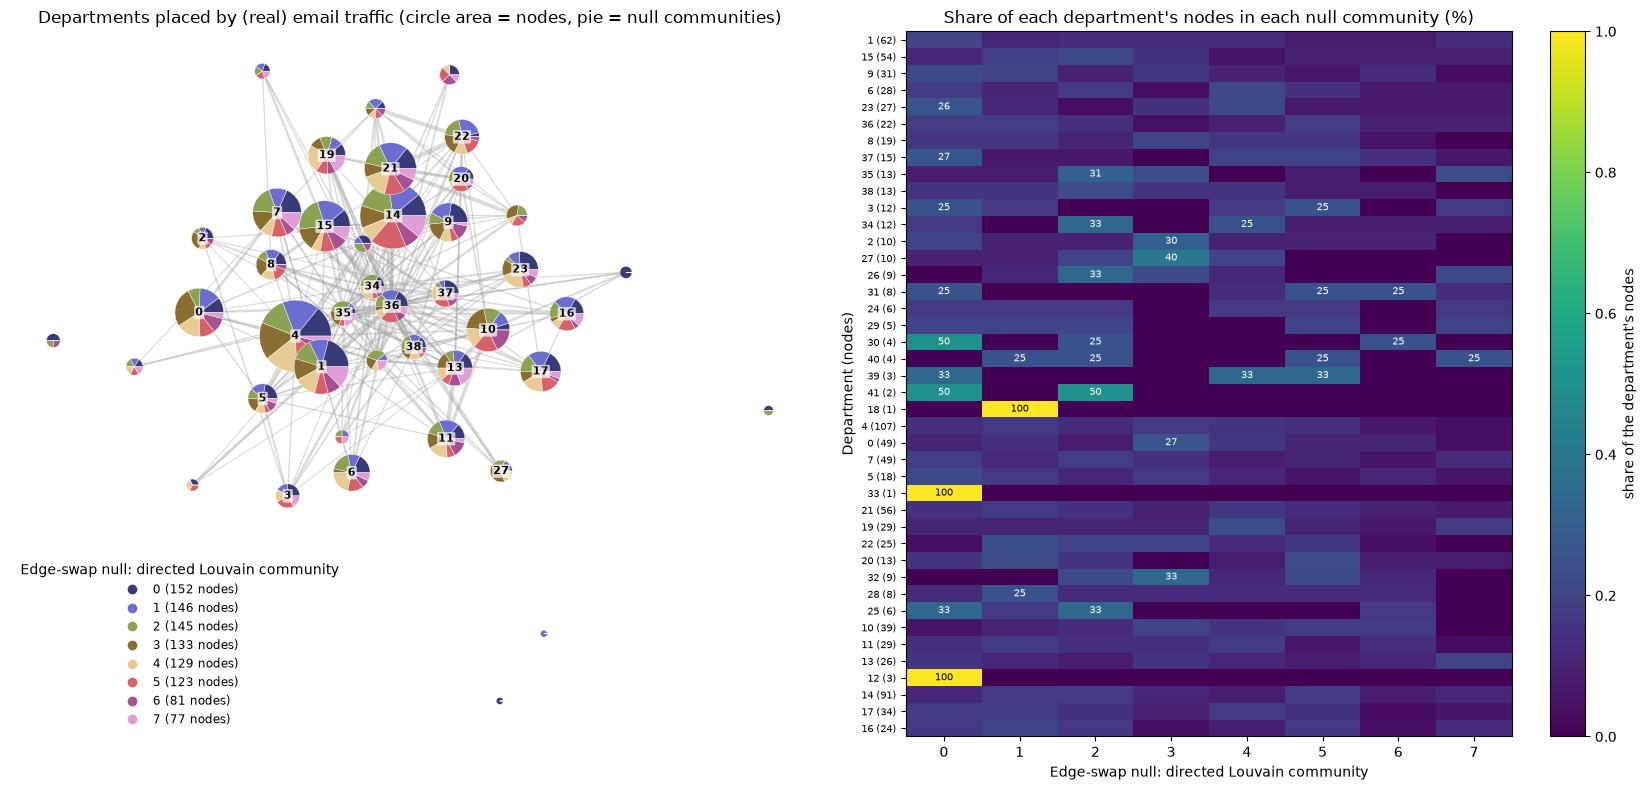

In [27]:
# same department-level figure as before, now for the randomized (edge-swap) partition
share_null = pd.crosstab(pd.Series(ground_truth, name="department"), pd.Series(partition_null, name="community"), normalize="index")
_, palette_null = community_colors(partition_null)
comm_sizes_null = Counter(partition_null.values())
fig, (ax_net, ax_heat) = plt.subplots(1, 2, figsize=(17, 8), dpi=100, gridspec_kw={"width_ratios": [1.1, 1]})
# left: each department is a pie of the null communities its nodes ended up in. circle area = department size
for a, b, d in H.edges(data=True):
    if d["weight"] >= cut:
        ax_net.plot(*zip(pos_dept[a], pos_dept[b]), color="0.6", alpha=0.35, lw=0.4 + 3 * d["weight"] / max(weights), zorder=1)
for d in dept_n.index:
    ax_net.pie(share_null.loc[d].values, colors=[palette_null[c] for c in share_null.columns], center=pos_dept[d],
               radius=0.009 * np.sqrt(dept_n[d]), frame=True, wedgeprops=dict(linewidth=0.3, edgecolor="white"))
    if dept_n[d] >= 10:
        ax_net.text(*pos_dept[d], str(d), ha="center", va="center", fontsize=8, fontweight="bold",
                    bbox=dict(boxstyle="round,pad=0.1", fc="white", ec="none", alpha=0.7), zorder=5)
handles = [Line2D([0], [0], marker="o", linestyle="", color=palette_null[c], label=f"{c} ({comm_sizes_null[c]} nodes)")
           for c in sorted(palette_null)]
ax_net.legend(handles=handles, title="Edge-swap null: directed Louvain community", loc="lower left", fontsize="small", frameon=False)
ax_net.set_aspect("equal")
ax_net.set_axis_off()
ax_net.set_title("Departments placed by (real) email traffic (circle area = nodes, pie = null communities)")

# right: the same table of shares, with the rows in the same department order as the real-network heatmap
im = ax_heat.imshow(share_null.loc[order].values, cmap="viridis", vmin=0, vmax=1, aspect="auto")
ax_heat.set_xticks(range(share_null.shape[1]), share_null.columns)
ax_heat.set_yticks(range(len(order)), [f"{d} ({dept_n[d]})" for d in order], fontsize=7)
for i, d in enumerate(order):
    for j, c in enumerate(share_null.columns):
        if share_null.loc[d, c] >= 0.25:
            ax_heat.text(j, i, f"{100 * share_null.loc[d, c]:.0f}", ha="center", va="center", fontsize=7,
                         color="white" if share_null.loc[d, c] < 0.6 else "black")
ax_heat.set_xlabel("Edge-swap null: directed Louvain community")
ax_heat.set_ylabel("Department (nodes)")
ax_heat.set_title("Share of each department's nodes in each null community (%)")
fig.colorbar(im, ax=ax_heat, label="share of the department's nodes")

fig.tight_layout()
fig.savefig("email_departments_vs_null_communities.png", dpi=300)
plt.show()

Now the figure the question asks for: the community size distribution of each partition, `partition_dir` on the left and `partition_null` on the right. With only 6 and 8 communities a histogram or a smoothed density would be mostly empty bins, so each community gets its own bar, ranked from largest to smallest (this shows the whole distribution). The y axis is log scaled since community sizes span more than a factor of five, and both panels share the same axes (same y limits, same x range) so the bar heights can be compared directly. The bar colors are the same ones used in the network figures.

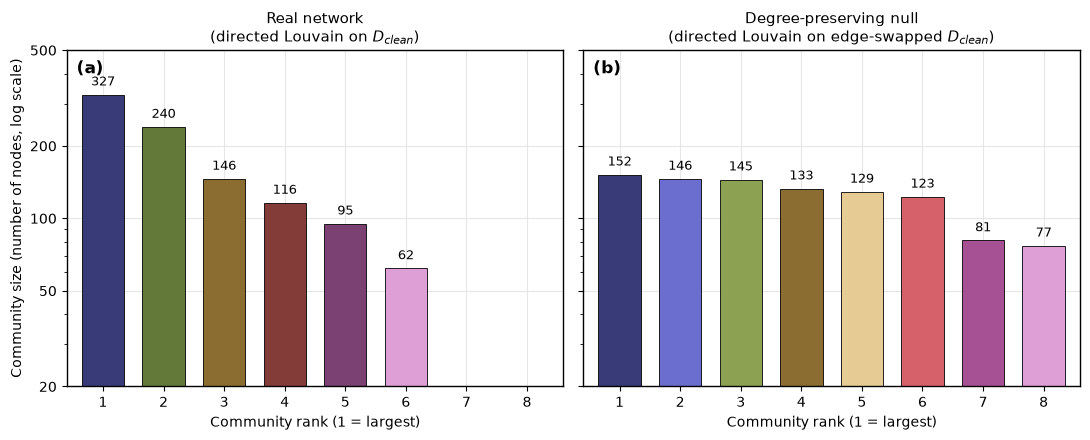

In [28]:
from matplotlib.ticker import ScalarFormatter, NullFormatter

# community size distributions: one bar per community, ranked by size, same axes in both panels
sizes_real = sorted(Counter(partition_dir.values()).values(), reverse=True)
sizes_null = sorted(Counter(partition_null.values()).values(), reverse=True)
_, palette_real = community_colors(partition_dir)
_, palette_null = community_colors(partition_null)

# theme_bw-ish (I miss R): white panel, light gray grid, black border
with plt.rc_context({"axes.facecolor": "white", "axes.edgecolor": "black", "axes.linewidth": 1,
                     "axes.grid": True, "grid.color": "0.9", "axes.axisbelow": True,
                     "axes.spines.top": True, "axes.spines.right": True}):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
    panels_c = [(sizes_real, palette_real, "Real network\n(directed Louvain on $D_{clean}$)", "(a)"),
                (sizes_null, palette_null, "Degree-preserving null\n(directed Louvain on edge-swapped $D_{clean}$)", "(b)")]
    for ax, (sizes, pal, title, tag) in zip(axes, panels_c):
        ranks = np.arange(1, len(sizes) + 1)
        # bars use the same tab20b colors as the network figures (rank 1 = community 0 = the largest)
        ax.bar(ranks, sizes, width=0.7, color=[pal[c] for c in sorted(pal)], edgecolor="black", linewidth=0.6)
        for r, s in zip(ranks, sizes):
            ax.text(r, s * 1.06, str(s), ha="center", va="bottom", fontsize=9)
        ax.set_yscale("log")
        ax.set_xlim(0.4, max(len(sizes_real), len(sizes_null)) + 0.6)
        ax.set_ylim(20, 500)
        # plain numbers on the log axis instead of powers of ten for non technical reader
        ax.set_yticks([20, 50, 100, 200, 500])
        ax.yaxis.set_major_formatter(ScalarFormatter())
        ax.yaxis.set_minor_formatter(NullFormatter())
        ax.set_xticks(range(1, max(len(sizes_real), len(sizes_null)) + 1))
        ax.set_xlabel("Community rank (1 = largest)")
        ax.set_title(title, fontsize=11)
        ax.text(0.02, 0.97, tag, transform=ax.transAxes, ha="left", va="top", fontsize=12, fontweight="bold")
    axes[0].set_ylabel("Community size (number of nodes, log scale)")
    fig.tight_layout()
    fig.savefig("community_size_distributions.png", dpi=300)
    plt.show()

The same two size distributions as a CCDF on a single set of axes, for direct comparison. For each community size $s$ it shows $P(S \geq s)$, the share of communities with at least $s$ nodes, with one marker per community and both axes on a log scale. A curve that reaches further to the right has larger communities, and one that drops steeply is made of communities with similar sizes, matching the visualization above.

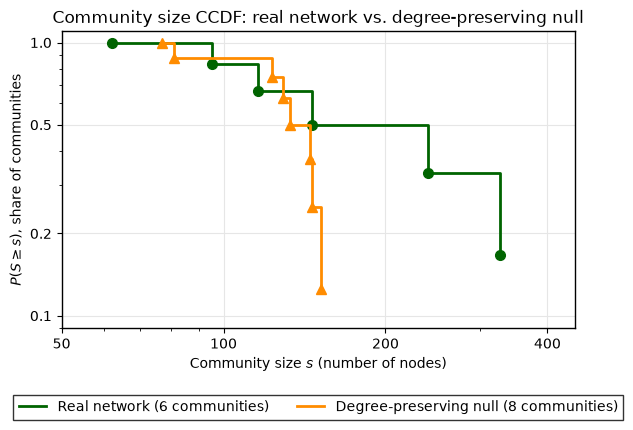

In [29]:
def size_ccdf(partition):
    # P(S >= s) at each community size s, where S is the size of a randomly chosen community
    sizes = np.sort(list(Counter(partition.values()).values()))
    return sizes, 1 - np.arange(len(sizes)) / len(sizes)

curves = {"Real network": (partition_dir, "darkgreen", "o"),
          "Degree-preserving null": (partition_null, "darkorange", "^")}

# same theme_bw-ish style as the other plots
with plt.rc_context({"axes.facecolor": "white", "axes.edgecolor": "black", "axes.linewidth": 1,
                     "axes.grid": True, "grid.color": "0.9", "axes.axisbelow": True,
                     "axes.spines.top": True, "axes.spines.right": True}):
    fig, ax = plt.subplots(figsize=(6.5, 4.5))
    for name, (partition, color, marker) in curves.items():
        s, p = size_ccdf(partition)
        # steps hold P(S >= s) flat until the next community size, one marker per community
        ax.step(s, p, where="post", color=color, linewidth=2, label=f"{name} ({len(s)} communities)")
        ax.plot(s, p, marker, color=color, markersize=7)
    ax.set_xscale("log")
    ax.set_yscale("log")
    # plain numbers on the log axes instead of powers of ten for non technical readers
    ax.set_xticks([50, 100, 200, 400])
    ax.set_yticks([0.1, 0.2, 0.5, 1])
    for axis in (ax.xaxis, ax.yaxis):
        axis.set_major_formatter(ScalarFormatter())
        axis.set_minor_formatter(NullFormatter())
    ax.set_xlim(50, 450)
    ax.set_ylim(0.09, 1.1)
    ax.set_xlabel("Community size $s$ (number of nodes)")
    ax.set_ylabel(r"$P(S \geq s)$, share of communities")
    ax.set_title("Community size CCDF: real network vs. degree-preserving null")
    # legend below the x axis label
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2, frameon=True, edgecolor="black", fancybox=False)
    fig.tight_layout()
    fig.savefig("community_size_ccdf.png", dpi=300, bbox_inches="tight")
    plt.show()

2.d

3.i

In [31]:
def preferentialGenerator(n, a, m=1, seed=None):
    '''
    grow a graph one node at a time with (nonlinear) preferential attachment
    start from a single node, then each new node t adds m edges to the existing nodes 0..t-1
    the m targets are drawn without replacement, so the graph stays simple
    m=1 by default, so the result is a tree with n - 1 edges
    return error for n < 1, a < 0, or m < 1
    make it reproducible
    '''
    if not isinstance(n, (int, np.integer)) or n < 1:
        raise ValueError("n must be a positive integer.")
    if a < 0:
        raise ValueError("a must be non-negative.")
    if not isinstance(m, (int, np.integer)) or m < 1:
        raise ValueError("m must be a positive integer.")
    rng = np.random.default_rng(seed)
    G = nx.Graph()
    G.add_nodes_from(range(n))
    # running degree of every node
    deg = np.zeros(n)
    for t in range(1, n):
        # weights of the existing nodes, the +1 gives degree-0 nodes a chance as well (from the question)
        w = deg[:t] ** a + 1
        # early on there can be fewer than m existing nodes to pick from
        targets = rng.choice(t, size=min(m, t), replace=False, p=w / w.sum())
        G.add_edges_from((t, int(j)) for j in targets)
        deg[targets] += 1
        deg[t] += len(targets)
    return G

The question only fixes `n` and `a`, so I've added `m` (the number of edges each new node brings) as an optional argument that defaults to 1. With `m=1` every graph is a tree, which keeps the degree comparison simple, and we can test differing `m` later.

Let's test it on small graphs with `seed=10` for reproducibility, and visualize one for each $\alpha$ from the question. Each graph should be a tree with $n - 1$ edges, and as $\alpha$ grows the edges should pile onto fewer and fewer hubs. Node size is scaled by degree so the hubs stand out.

a = 0.1: 50 nodes, 49 edges, tree: True, max degree = 5
a = 1: 50 nodes, 49 edges, tree: True, max degree = 11
a = 2: 50 nodes, 49 edges, tree: True, max degree = 25


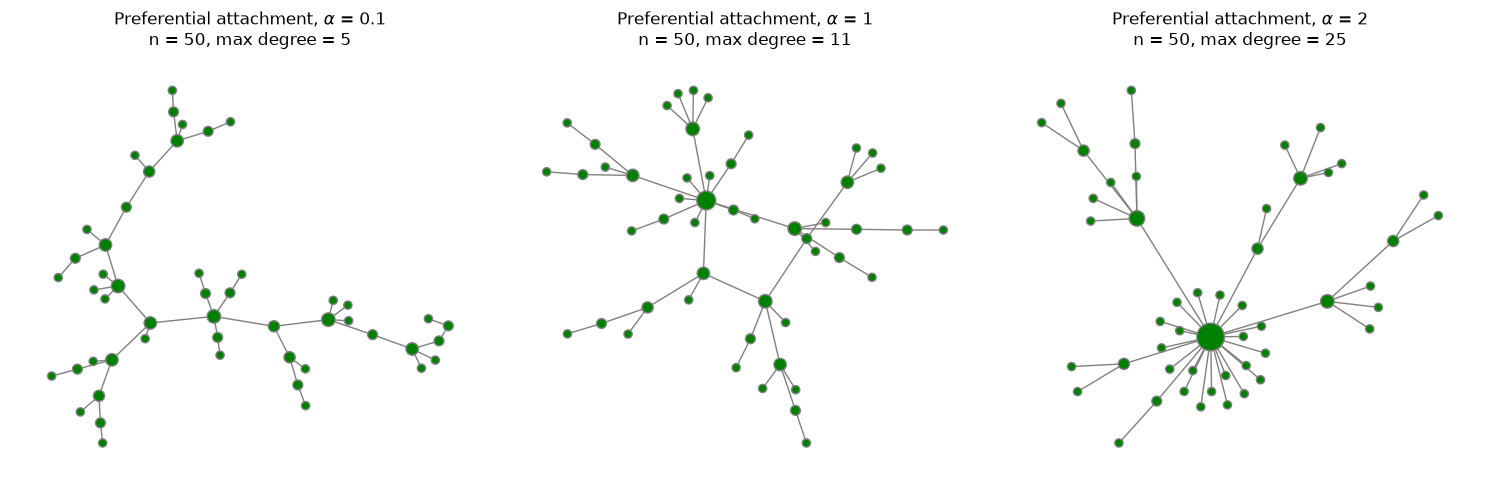

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, a in zip(axes, [0.1, 1, 2]):
    G = preferentialGenerator(50, a, seed=10)
    k = dict(G.degree())
    print(f"a = {a}: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges, tree: {nx.is_tree(G)}, max degree = {max(k.values())}")
    pos = nx.spring_layout(G, seed=10)
    # node area grows with degree so the hubs are easy to spot
    nx.draw_networkx_nodes(G, pos, node_color="green", edgecolors="grey", node_size=[20 + 15 * k[v] for v in G], ax=ax)
    nx.draw_networkx_edges(G, pos, edge_color="0.5", ax=ax)
    ax.set_title(f"Preferential attachment, $\\alpha$ = {a}\nn = 50, max degree = {max(k.values())}")
    ax.set_axis_off()
fig.tight_layout()
plt.show()

3.ii

We grow graphs with $n = 1000$ and $\alpha \in \{0.1, 1, 2\}$. As in question 2, we will compare by grow 20 graphs per $\alpha$ (graph $i$ uses `seed=10+i`) and pool the degrees of all of their nodes. We plot the CCDF, $P(K \geq k)$, on log-log axes. The CCDF means we don't have to pick bins, which matters here because the three degree ranges are very different.

For reference, the dashed line has slope $-3$, which is the CCDF of a power law $p_k \sim k^{-4}$. That is the exponent expected for linear attachment with the $+1$ shift and $m = 1$ (the shift makes the tail steeper than the classic Barabási-Albert $k^{-3}$).

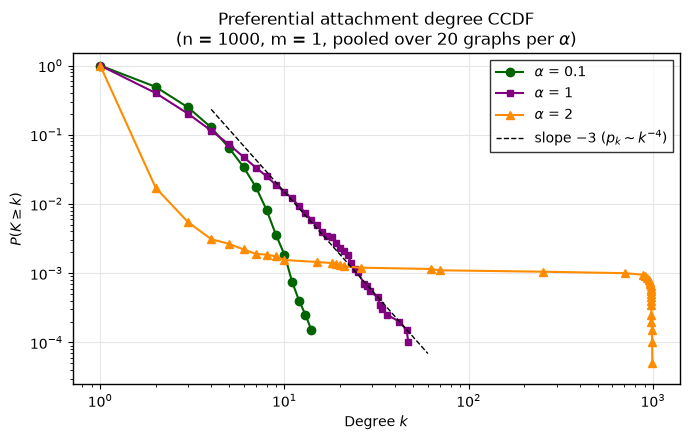

a = 0.1: share of nodes with degree 1 = 0.508, share with degree >= 10 = 0.0019
a = 1: share of nodes with degree 1 = 0.600, share with degree >= 10 = 0.0149
a = 2: share of nodes with degree 1 = 0.983, share with degree >= 10 = 0.0015


In [33]:
from matplotlib.ticker import NullFormatter

def value_ccdf(values):
    # P(X >= x) at every distinct value x in the sample
    values = np.sort(np.asarray(values))
    x = np.unique(values)
    return x, 1 - np.searchsorted(values, x, side="left") / len(values)

n_gen = 1000
n_seeds = 20
alphas = [0.1, 1, 2]

# 20 graphs per alpha, pool every node's degree, and keep the biggest hub of each graph for the table below
pa_degrees = {a: [] for a in alphas}
pa_rows = []
for i in range(n_seeds):
    row = {}
    for a in alphas:
        G = preferentialGenerator(n_gen, a, seed=10 + i)
        k = [d for _, d in G.degree()]
        pa_degrees[a].extend(k)
        row[f"max degree (a={a})"] = max(k)
        # with m=1 there are n - 1 edges, so this is the share of all edges that touch the biggest hub
        row[f"hub share of edges (a={a})"] = max(k) / G.number_of_edges()
    pa_rows.append(row)

colors_a = {0.1: "darkgreen", 1: "purple", 2: "darkorange"}
markers_a = {0.1: ("o", 6), 1: ("s", 4), 2: ("^", 6)}

with plt.rc_context({"axes.facecolor": "white", "axes.edgecolor": "black", "axes.linewidth": 1,
                     "axes.grid": True, "grid.color": "0.9", "axes.axisbelow": True,
                     "axes.spines.top": True, "axes.spines.right": True}):
    fig, ax = plt.subplots(figsize=(7, 4.5))
    for a in alphas:
        x, p = value_ccdf(pa_degrees[a])
        m, ms = markers_a[a]
        ax.plot(x, p, marker=m, markersize=ms, linewidth=1.5, color=colors_a[a], label=f"$\\alpha$ = {a}")
    # reference slope of -3 (p_k ~ k^-4), anchored on the alpha = 1 curve at k = 10 where the tail starts
    x1, p1 = value_ccdf(pa_degrees[1])
    k_ref = np.array([4, 60])
    ax.plot(k_ref, p1[x1 == 10][0] * (k_ref / 10) ** -3.0, "k--", linewidth=1, label="slope $-3$ ($p_k \\sim k^{-4}$)")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_ylim(1 / (2 * n_seeds * n_gen), 1.5)
    ax.set_xlabel("Degree $k$")
    ax.set_ylabel(r"$P(K \geq k)$")
    ax.set_title(f"Preferential attachment degree CCDF\n(n = {n_gen}, m = 1, pooled over {n_seeds} graphs per $\\alpha$)")
    ax.legend(frameon=True, edgecolor="black", fancybox=False)
    fig.tight_layout()
    fig.savefig("preferential_degree_ccdf.png", dpi=300)
    plt.show()

for a in alphas:
    k = np.array(pa_degrees[a])
    print(f"a = {a}: share of nodes with degree 1 = {(k == 1).mean():.3f}, share with degree >= 10 = {(k >= 10).mean():.4f}")

And the biggest hub in each of the 20 graphs per $\alpha$, which shows how much the superlinear case concentrates the edges.

In [34]:
pd.DataFrame(pa_rows).agg(["mean", "std", "min", "max"]).T.round(3)

,mean,std,min,max
max degree (a=0.1),11.250,1.682,9.000,14.000
hub share of edges (a=0.1),0.011,0.002,0.009,0.014
max degree (a=1),31.150,8.659,18.000,47.000
hub share of edges (a=1),0.031,0.009,0.018,0.047
max degree (a=2),949.800,65.524,701.000,992.000
hub share of edges (a=2),0.951,0.066,0.702,0.993


The three curves line up with the three regimes. At $\alpha = 0.1$ the preference is so weak that every existing node is close to equally likely, and the CCDF bends down quickly (the curve gets steeper and steeper on the log-log axes), with no node past degree 14 in any of the 20 graphs. At $\alpha = 1$ the tail is much longer and, past about $k = 10$, roughly parallel to the slope $-3$ guide, which is the heavy tail we would expect from linear preferential attachment. With only 1000 nodes the tail covers barely more than one decade of $k$, so this is a consistency check rather than a fit. At $\alpha = 2$ almost every node has degree 1, and the rest of the curve is the single hub at around $k \approx 950$: the rich get so much richer that one node ends up connected to nearly everyone (a star).

3.iii

In [35]:
def randomWalkGenerator(n, p, seed=None):
    '''
    grow a graph one node at a time with the random walk model
    start from a triangle on nodes 0, 1, 2, so every node already has neighbors to walk to
    each new node i first adds an edge to a uniformly random existing node j
    then with probability p it adds an edge to a random neighbor of j (closing the triangle i, j, neighbor)
    otherwise it adds an edge to another uniformly random existing node (not j)
    the graph stays simple and has 3 + 2(n - 3) edges
    return error for n < 3 or p outside [0, 1]
    make it reproducible with a seed for the random number generator
    '''
    if not isinstance(n, (int, np.integer)) or n < 3:
        raise ValueError("n must be an integer of at least 3.")
    if not 0 <= p <= 1:
        raise ValueError("p must be between 0 and 1.")
    rng = np.random.default_rng(seed)
    G = nx.complete_graph(3)
    for i in range(3, n):
        j = int(rng.integers(i))
        if rng.random() < p:
            # take the neighbors of j before i is attached, so the walk can't step back onto i
            second = int(rng.choice(list(G.neighbors(j))))
        else:
            # any existing node except j: draw from the other i - 1 nodes and skip over j
            second = int(rng.integers(i - 1))
            second += second >= j
        G.add_edges_from([(i, j), (i, second)])
    return G

The model needs a starting graph where the first random node $j$ already has a neighbor to walk to, so we seed it with a triangle (a single edge would also work, but then the first node's walk could only go back to the other end of that edge).

Let's test it on small graphs, with `seed=10` for reproducibility, and visualize the two extremes $p = 0$ and $p = 0.9$. Every new node brings exactly two edges and both go to distinct existing nodes, so the graph should be simple with $3 + 2(n - 3)$ edges. With $p = 0.9$ most new nodes close a triangle, so we should see many more triangles than for $p = 0$.

p = 0: 30 nodes, 57 edges (expected 57), self-loops: 0, triangles: 9
p = 0.9: 30 nodes, 57 edges (expected 57), self-loops: 0, triangles: 25


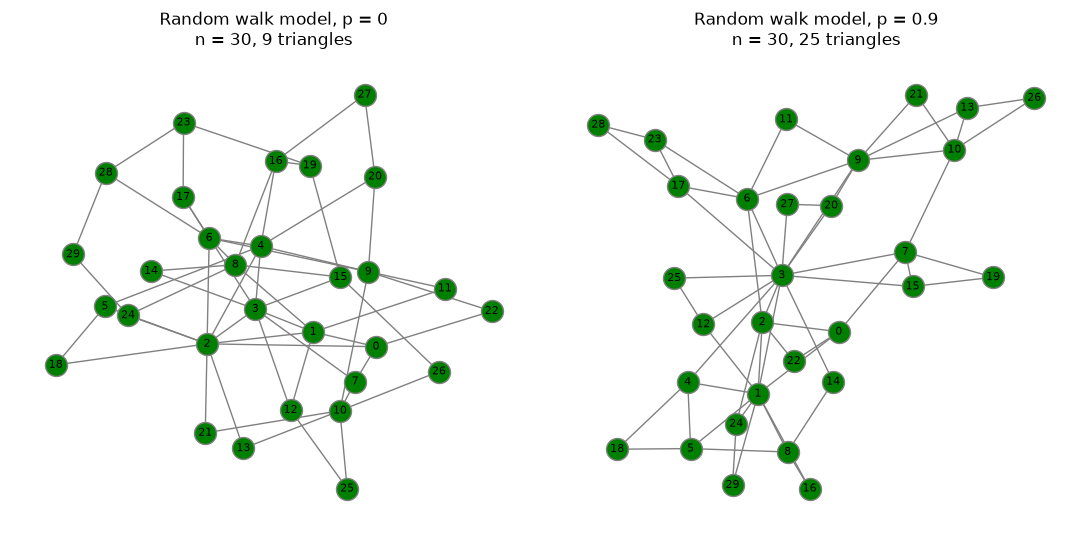

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5.5))
for ax, p in zip(axes, [0, 0.9]):
    G = randomWalkGenerator(30, p, seed=10)
    n_tri = sum(nx.triangles(G).values()) // 3
    print(f"p = {p}: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges (expected {3 + 2 * (30 - 3)}), "
          f"self-loops: {nx.number_of_selfloops(G)}, triangles: {n_tri}")
    pos = nx.spring_layout(G, seed=10)
    nx.draw_networkx_nodes(G, pos, node_color="green", edgecolors="grey", node_size=250, ax=ax)
    nx.draw_networkx_labels(G, pos, font_size=8, ax=ax)
    nx.draw_networkx_edges(G, pos, edge_color="0.5", ax=ax)
    ax.set_title(f"Random walk model, p = {p}\nn = 30, {n_tri} triangles")
    ax.set_axis_off()
fig.tight_layout()
plt.show()

Now we can test for bad inputs. Fewer than 3 nodes can't hold the starting triangle, and $p$ is a probability, so these should all raise a ValueError.

In [37]:
# n too small, p below 0, p above 1
for bad in ((2, 0.5), (10, -0.1), (10, 1.5)):
    try:
        randomWalkGenerator(*bad)
    except ValueError as e:
        print(bad, "->", e)

(2, 0.5) -> n must be an integer of at least 3.
(10, -0.1) -> p must be between 0 and 1.
(10, 1.5) -> p must be between 0 and 1.


3.iv

We grow graphs with $n = 1000$ and $p \in \{0, 0.1, 0.5, 0.9\}$, again 20 graphs per $p$ with `seed=10+i`, and pool the local clustering coefficient of every node, $C_i = \frac{\text{triangles through } i}{\binom{k_i}{2}}$. The figure has two panels:

- (a) the CCDF of $C$, $P(C \geq c)$. Clustering lives in $[0, 1]$, so the x axis is linear, but the y axis is log scaled since at $p = 0$ only about 5% of nodes have any clustering at all.
- (b) the average clustering of the nodes with degree $k$, $C(k)$, on log-log axes, which shows *where* in the graph the triangles are. Degrees held by fewer than 10 pooled nodes are left out because their averages are too noisy, and zero averages (most of $p = 0$) can't be drawn on a log scale.

Every node starts with degree 2, and a degree-2 node whose second edge went to a neighbor of $j$ sits in exactly one triangle out of one possible, so $C = 1$. We should therefore see a big jump at $c = 1$ that grows with $p$.

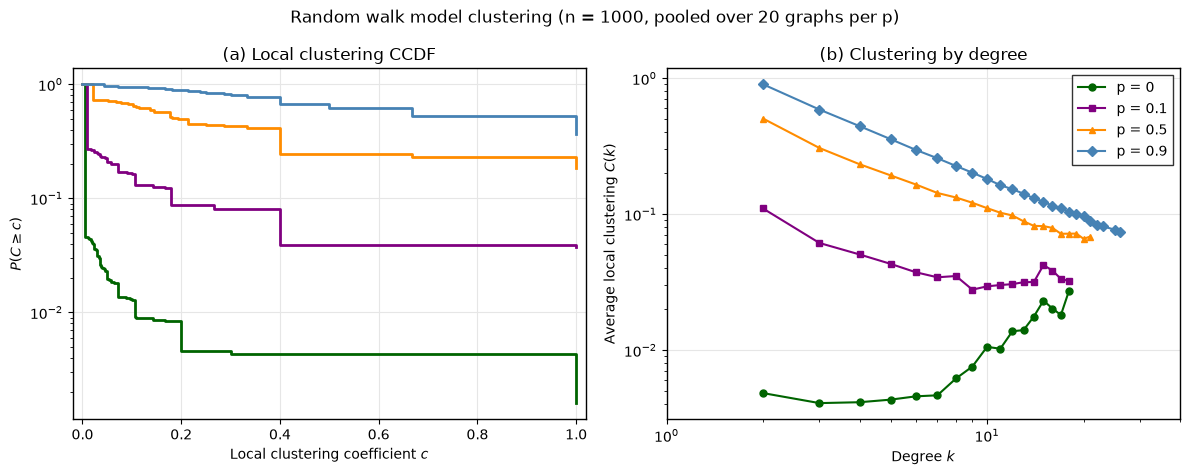

p = 0: mean C = 0.005, share with C > 0 = 0.046, share with C = 1 = 0.002
p = 0.1: mean C = 0.069, share with C > 0 = 0.270, share with C = 1 = 0.037
p = 0.5: mean C = 0.327, share with C > 0 = 0.728, share with C = 1 = 0.185
p = 0.9: mean C = 0.614, share with C > 0 = 0.958, share with C = 1 = 0.365


In [38]:
ps = [0, 0.1, 0.5, 0.9]

# 20 graphs per p, pool every node's clustering and degree (the degrees are reused in 3.v), and keep the per-graph averages for the table below
rw_clustering = {p: [] for p in ps}
rw_degrees = {p: [] for p in ps}
rw_rows = []
for i in range(n_seeds):
    row = {}
    for p in ps:
        G = randomWalkGenerator(n_gen, p, seed=10 + i)
        c = nx.clustering(G)
        rw_clustering[p].extend(c[v] for v in G)
        rw_degrees[p].extend(G.degree(v) for v in G)
        row[f"mean local clustering (p={p})"] = np.mean(list(c.values()))
        row[f"transitivity (p={p})"] = nx.transitivity(G)
    rw_rows.append(row)

colors_p = {0: "darkgreen", 0.1: "purple", 0.5: "darkorange", 0.9: "steelblue"}
markers_p = {0: "o", 0.1: "s", 0.5: "^", 0.9: "D"}

# same theme_bw-ish style as the other plots
with plt.rc_context({"axes.facecolor": "white", "axes.edgecolor": "black", "axes.linewidth": 1,
                     "axes.grid": True, "grid.color": "0.9", "axes.axisbelow": True,
                     "axes.spines.top": True, "axes.spines.right": True}):
    fig, (ax_c, ax_k) = plt.subplots(1, 2, figsize=(12, 4.8))
    for p in ps:
        # (a) CCDF of the local clustering, drawn as steps since C takes many distinct values
        x, cc = value_ccdf(rw_clustering[p])
        ax_c.step(x, cc, where="post", color=colors_p[p], linewidth=2, label=f"p = {p}")
        # (b) average clustering by degree, only degrees held by at least 10 pooled nodes
        ck = pd.DataFrame({"k": rw_degrees[p], "C": rw_clustering[p]}).groupby("k")["C"].agg(["mean", "size"])
        ck = ck[(ck["size"] >= 10) & (ck["mean"] > 0)]
        ax_k.plot(ck.index, ck["mean"], marker=markers_p[p], markersize=5, linewidth=1.5, color=colors_p[p], label=f"p = {p}")
    ax_c.set_yscale("log")
    ax_c.set_xlim(-0.02, 1.02)
    ax_c.set_xlabel("Local clustering coefficient $c$")
    ax_c.set_ylabel(r"$P(C \geq c)$")
    ax_c.set_title("(a) Local clustering CCDF")
    ax_k.set_xscale("log")
    ax_k.set_yscale("log")
    # the degree range is about one decade, so hide the minor tick labels and only label the powers of ten
    ax_k.xaxis.set_minor_formatter(NullFormatter())
    ax_k.set_xlim(1, 40)
    ax_k.set_xlabel("Degree $k$")
    ax_k.set_ylabel("Average local clustering $C(k)$")
    ax_k.set_title("(b) Clustering by degree")
    ax_k.legend(frameon=True, edgecolor="black", fancybox=False)
    fig.suptitle(f"Random walk model clustering (n = {n_gen}, pooled over {n_seeds} graphs per p)")
    fig.tight_layout()
    fig.savefig("random_walk_clustering.png", dpi=300)
    plt.show()

for p in ps:
    c = np.array(rw_clustering[p])
    print(f"p = {p}: mean C = {c.mean():.3f}, share with C > 0 = {(c > 0).mean():.3f}, share with C = 1 = {(c == 1).mean():.3f}")

The average clustering of each graph across the 20 seeds. Transitivity is the global version (three times the triangles over the connected triples), which weights the hubs much more than the mean of $C_i$ does.

In [39]:
pd.DataFrame(rw_rows).agg(["mean", "std", "min", "max"]).T.round(3)

,mean,std,min,max
mean local clustering (p=0),0.005,0.001,0.003,0.008
transitivity (p=0),0.008,0.001,0.006,0.011
mean local clustering (p=0.1),0.069,0.008,0.051,0.086
transitivity (p=0.1),0.041,0.003,0.035,0.046
mean local clustering (p=0.5),0.327,0.011,0.306,0.345
transitivity (p=0.5),0.157,0.005,0.148,0.166
mean local clustering (p=0.9),0.614,0.009,0.595,0.628
transitivity (p=0.9),0.242,0.007,0.229,0.254


Clustering grows steadily with $p$, from essentially none at $p = 0$ (there the second edge goes to a uniformly random node, so a triangle only happens by chance) to a mean local clustering of about 0.6 at $p = 0.9$. A big part of that is the value where each curve in panel (a) ends, $P(C \geq 1)$: at $p = 0.9$ about 37% of all nodes have $C = 1$ exactly, and those are the low-degree nodes whose two edges closed a triangle. Panel (b) shows that for $p = 0.5$ and $p = 0.9$ the clustering is concentrated in the low-degree nodes and falls off roughly as $1/k$ for the hubs (a factor of 10 in $k$ costs about a factor of 10 in $C(k)$), which is also why the transitivity is lower than the mean local clustering. At $p = 0$ the trend runs the other way, but there the few triangles are chance ones, and they collect around the oldest nodes, which have the most edges and are mostly connected to each other.

3.v

To support the comparison, we put both models side by side on the same metrics, again averaged over 20 graphs each with $n = 1000$. We include preferential attachment with $\alpha = 1$ for both `m=1` (as in 3.ii) and `m=2`, since `m=2` adds the same two edges per new node as the random walk model, so those graphs have about the same number of edges.

In [40]:
models = {"Preferential (a=1, m=1)": lambda s: preferentialGenerator(n_gen, 1, seed=s),
          "Preferential (a=1, m=2)": lambda s: preferentialGenerator(n_gen, 1, m=2, seed=s)}
models.update({f"Random walk (p={p})": (lambda s, p=p: randomWalkGenerator(n_gen, p, seed=s)) for p in ps})

# same 20 seeds per model, average every metric over the 20 graphs. keep the pa m=2 degrees for the next plot
summary = []
pa2_degrees = []
for name, gen in models.items():
    rows = []
    for i in range(n_seeds):
        G = gen(10 + i)
        k = [d for _, d in G.degree()]
        if name == "Preferential (a=1, m=2)":
            pa2_degrees.extend(k)
        rows.append({"edges": G.number_of_edges(), "max degree": max(k),
                     "mean local clustering": nx.average_clustering(G), "transitivity": nx.transitivity(G),
                     "degree assortativity": nx.degree_assortativity_coefficient(G),
                     # every graph from both models is connected, so the average path length is defined
                     "average path length": nx.average_shortest_path_length(G)})
    summary.append(pd.DataFrame(rows).mean().rename(name))
pd.DataFrame(summary).round(3)

,edges,max degree,mean local clustering,transitivity,degree assortativity,average path length
"Preferential (a=1, m=1)",999.0,31.15,0.000,0.000,-0.083,8.553
"Preferential (a=1, m=2)",1997.0,58.55,0.016,0.010,-0.047,4.308
Random walk (p=0),1997.0,18.55,0.005,0.008,0.134,4.939
Random walk (p=0.1),1997.0,19.30,0.069,0.041,0.122,4.987
Random walk (p=0.5),1997.0,24.40,0.327,0.157,0.087,5.254
Random walk (p=0.9),1997.0,33.75,0.614,0.242,0.032,5.835


One more check: the random walk step doesn't look at degrees at all, but a random neighbor of a random node is more likely to be a high-degree node (a node with $k$ neighbors can be reached from $k$ different $j$'s, the friendship paradox). So the walk step is a hidden form of linear preferential attachment, and the random walk graphs should get heavier degree tails as $p$ grows. We reuse the pooled degrees from 3.iv and compare them to preferential attachment with $\alpha = 1$, `m=2` (dashed).

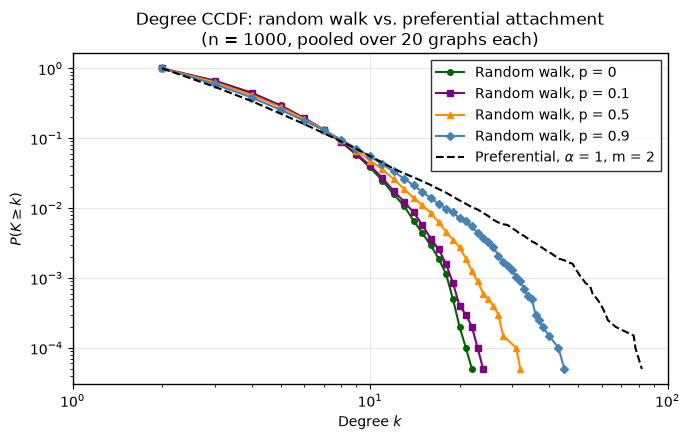

In [41]:
# same theme_bw-ish style as the other plots
with plt.rc_context({"axes.facecolor": "white", "axes.edgecolor": "black", "axes.linewidth": 1,
                     "axes.grid": True, "grid.color": "0.9", "axes.axisbelow": True,
                     "axes.spines.top": True, "axes.spines.right": True}):
    fig, ax = plt.subplots(figsize=(7, 4.5))
    for p in ps:
        x, cc = value_ccdf(rw_degrees[p])
        ax.plot(x, cc, marker=markers_p[p], markersize=4, linewidth=1.5, color=colors_p[p], label=f"Random walk, p = {p}")
    x, cc = value_ccdf(pa2_degrees)
    ax.plot(x, cc, "k--", linewidth=1.5, label="Preferential, $\\alpha$ = 1, m = 2")
    ax.set_xscale("log")
    ax.set_yscale("log")
    # the degree range is under two decades, so hide the minor tick labels and only label the powers of ten
    ax.xaxis.set_minor_formatter(NullFormatter())
    ax.set_xlim(1, 100)
    ax.set_xlabel("Degree $k$")
    ax.set_ylabel(r"$P(K \geq k)$")
    ax.set_title(f"Degree CCDF: random walk vs. preferential attachment\n(n = {n_gen}, pooled over {n_seeds} graphs each)")
    ax.legend(frameon=True, edgecolor="black", fancybox=False)
    fig.tight_layout()
    fig.savefig("random_walk_degree_ccdf.png", dpi=300)
    plt.show()

The random walk tails do get heavier as $p$ grows, but even at $p = 0.9$ they stay lighter than preferential attachment with the same number of edges. That makes sense, since only the second edge of each new node, and only with probability $p$, is degree-biased: the first edge is always uniform, so the effective attachment rule is a mix of uniform and linear. The table shows the other side of the trade: preferential attachment has essentially no clustering (exactly none for `m=1`, since it is a tree) and is slightly disassortative (new leaves attach to the hubs), while the random walk graphs gain clustering with $p$ and are assortative (the oldest nodes have the most edges and are mostly connected to each other). The average path lengths are all short, but the triangles in the random walk model make it a little longer as $p$ grows, since closing a triangle reuses a local edge instead of reaching across the graph.